# Coeliac mutagenesis analysis

In this notebook we try to recreate the results of the paper that the α1 peptide is a stronger binder than the ω1 peptide and that disrupting the 'WD' motif in the CDR3β will reduce binding to both epitopes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences = pd.read_csv('../data/interim/sequences_coeliac_mutations.csv', index_col='id')

In [4]:
sequences['wd_motif'] = sequences['cdr3_beta'].map(lambda cdr3_beta: 'WD' in cdr3_beta)

In [5]:
sequences['original'] = sequences.index.map(lambda id_: 'original' in id_)

cdr3_alpha = sequences[sequences['original']]['cdr3_alpha'].unique()[0]
sequences_beta_only_mutations = sequences[sequences['cdr3_alpha'] == cdr3_alpha]

In [6]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_coeliac_mutations.csv')

In [7]:
confidence_scores = confidence_scores.merge(
    sequences_beta_only_mutations, how='inner', left_on='name', right_index=True
)

## Structure prediction quality

In [8]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80

In [9]:
dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_coeliac.csv')
dockq_scores[['name', 'reference_structure']] = dockq_scores['name'].str.split('-').apply(pd.Series)

In [10]:
dockq_scores = dockq_scores.merge(confidence_scores, how='inner', on=['name', 'seed', 'sample'])

In [11]:
dockq_scores['top_rank'] = False
dockq_scores.loc[dockq_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

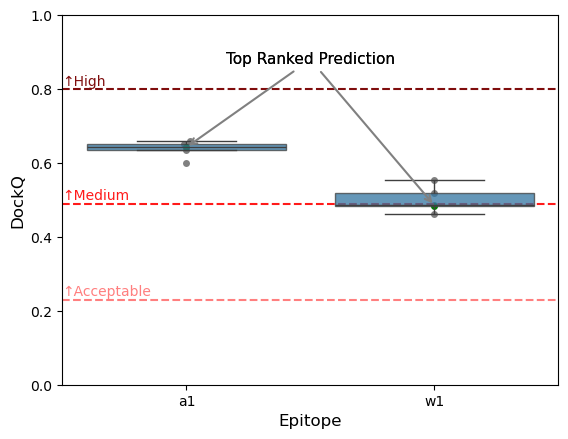

In [12]:
fig, ax = plt.subplots(1, 1)

for label, cutoff, colour in (
    ('↑Acceptable', CAPRI_ACCEPTABLE_CUTOFF, '#ff7f7f'),
    ('↑Medium', CAPRI_MEDIUM_CUTOFF, '#ff1a1a'),
    ('↑High', CAPRI_HIGH_CUTOFF, '#7f0d0d'),
):
    ax.text(-0.5, cutoff + 0.01, label, color=colour)
    ax.axhline(cutoff, linestyle='dashed', color=colour)

sns.boxplot(
    dockq_scores,
    x='pmhc_calls',
    y='DockQ',
    color='tab:blue',
    showfliers=False,
    boxprops={'alpha': 0.75},
    zorder=2,
    ax=ax,
)
sns.swarmplot(dockq_scores.query('not top_rank'), y='DockQ', x='pmhc_calls', color='grey', zorder=1, ax=ax)
sns.swarmplot(dockq_scores.query('top_rank'), y='DockQ', x='pmhc_calls', color='green', zorder=1, ax=ax)

for _, pmhc_calls, dockq in dockq_scores.query('top_rank')[['pmhc_calls', 'DockQ']].itertuples():
    ax.annotate(
        'Top Ranked Prediction',
        xy=(pmhc_calls, dockq),
        xycoords='data',
        xytext=(0.50, 0.90),
        textcoords='axes fraction',
        va='top',
        ha='center',
        arrowprops={'arrowstyle': '->', 'color': 'gray', 'lw': 1.5},
        fontsize=11,
    )

ax.set_ylim([0.0, 1.0])

ax.set_ylabel(ax.get_ylabel(), fontsize=12)
ax.set_xlabel('Epitope', fontsize=12)

plt.show()

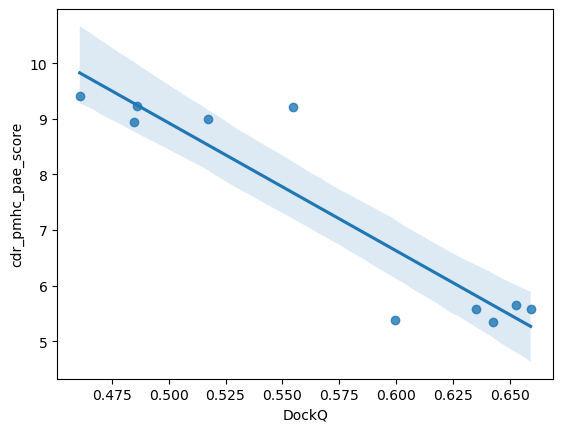

In [13]:
sns.regplot(dockq_scores, x='DockQ', y='cdr_pmhc_pae_score')
plt.show()

In [14]:
result = pg.corr(dockq_scores['DockQ'], dockq_scores['cdr_pmhc_pae_score'], alternative='less')

print(f"R^2 = {result.iloc[0]['r'] ** 2:.2f}")
result

R^2 = 0.86


,n,r,CI95%,p-val,BF10,power
pearson,10,-0.926876,"[-1.0, -0.77]",0.000057,430.664,0.997675


## Epitope baseline binding score

In [15]:
confidence_scores.value_counts(['pmhc_calls', 'wd_motif']).sort_index()

pmhc_calls  wd_motif
a1          False       10
            True        35
w1          False       10
            True        35
Name: count, dtype: int64

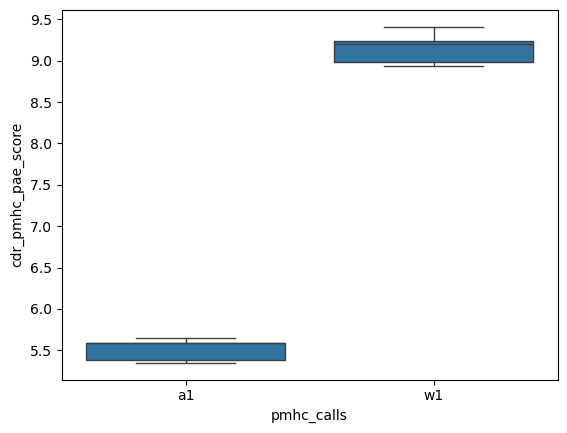

In [16]:
sns.boxplot(confidence_scores.query('original'), x='pmhc_calls', y='cdr_pmhc_pae_score')

plt.show()

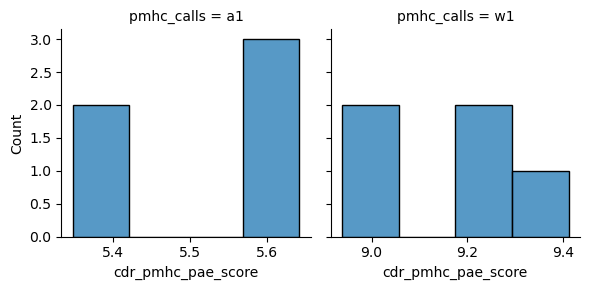

In [17]:
grid = sns.FacetGrid(confidence_scores.query('original'), col='pmhc_calls', sharex=False)
grid.map_dataframe(sns.histplot, x='cdr_pmhc_pae_score')

plt.show()

In [18]:
result = pg.mwu(
    confidence_scores.query("original and pmhc_calls == 'a1'")['cdr_pmhc_pae_score'],
    confidence_scores.query("original and pmhc_calls == 'w1'")['cdr_pmhc_pae_score'],
    alternative='less',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,0.0,less,0.003968,-1.0,1.0,True


## Mutagenesis analysis

In [19]:
confidence_scores_mutations = confidence_scores.query('not original')

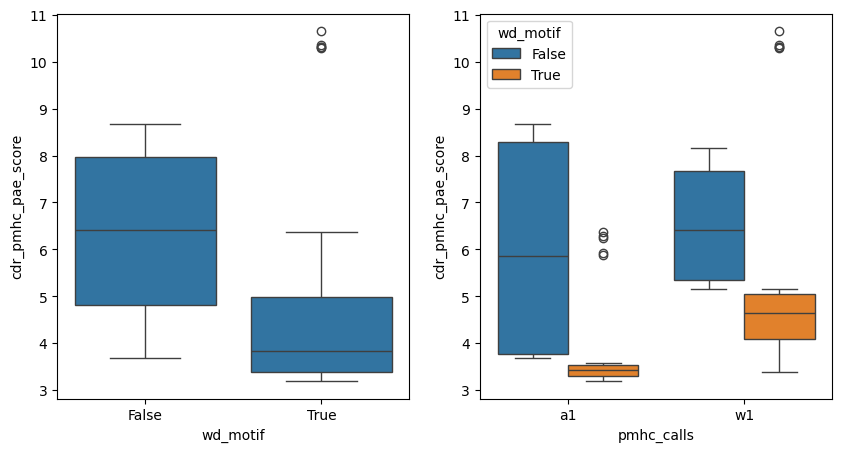

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(confidence_scores_mutations, x='wd_motif', y='cdr_pmhc_pae_score', ax=axes[0])
sns.boxplot(confidence_scores_mutations, x='pmhc_calls', y='cdr_pmhc_pae_score', hue='wd_motif', ax=axes[1])

plt.show()

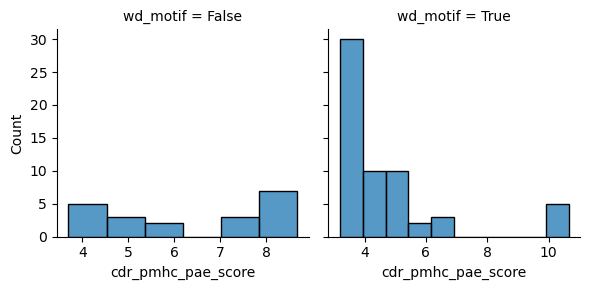

In [21]:
grid = sns.FacetGrid(confidence_scores_mutations, col='wd_motif', sharex=False)
grid.map_dataframe(sns.histplot, x='cdr_pmhc_pae_score')

plt.show()

In [22]:
result = pg.mwu(
    confidence_scores.query('not original and wd_motif')['cdr_pmhc_pae_score'],
    confidence_scores.query('not original and not wd_motif')['cdr_pmhc_pae_score'],
    alternative='less',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,252.0,less,0.000056,-0.58,0.79,True


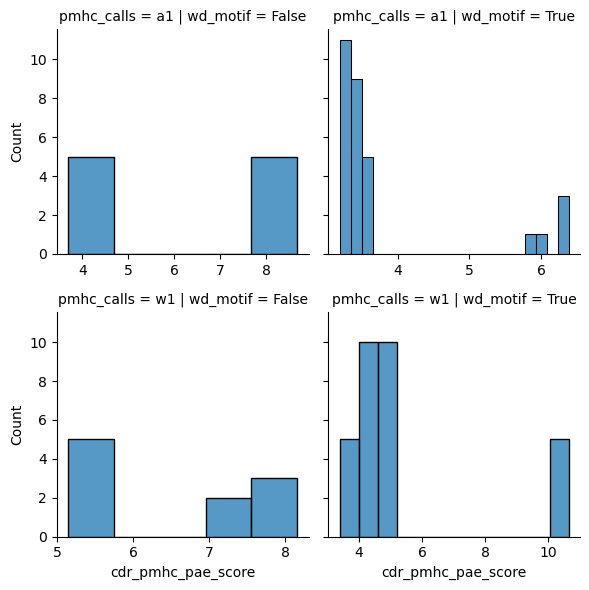

In [23]:
grid = sns.FacetGrid(confidence_scores_mutations, row='pmhc_calls', col='wd_motif', sharex=False)
grid.map_dataframe(sns.histplot, x='cdr_pmhc_pae_score')

plt.show()

In [24]:
result = pg.anova(confidence_scores_mutations, dv='cdr_pmhc_pae_score', between=['pmhc_calls', 'wd_motif'])
result['significant'] = result['p-unc'] < SIGNIFICANCE_LEVEL

result

,Source,SS,DF,MS,F,p-unc,np2,significant
0,pmhc_calls,33.218040,1.0,33.218040,9.800638,0.002476,0.114226,True
1,wd_motif,40.411722,1.0,40.411722,11.923059,0.000909,0.135608,True
2,pmhc_calls * wd_motif,4.109853,1.0,4.109853,1.212569,0.274299,0.015704,False
3,Residual,257.592528,76.0,3.389375,NaN,NaN,NaN,False


In [25]:
results = []

for pmhc_calls, epitope_group in confidence_scores_mutations.groupby('pmhc_calls'):
    result = pg.ttest(
        epitope_group.query('wd_motif')['cdr_pmhc_pae_score'],
        epitope_group.query('not wd_motif')['cdr_pmhc_pae_score'],
        alternative='less',
    )
    result['epitope_name'] = pmhc_calls

    results.append(result)

results = pd.concat(results)
results = results.set_index('epitope_name')
results['significant'] = results['p-val'] < (SIGNIFICANCE_LEVEL / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
epitope_name,,,,,,,,,
a1,-2.763399,10.181448,less,0.009851,"[-inf, -0.75]",1.454737,10.955,0.988298,True
w1,-1.883332,28.383234,less,0.034970,"[-inf, -0.11]",0.523277,2.568,0.406191,False


## Correlation between confidence score and SPR

In [26]:
affinities = {
    'coeliac_a1_mut_original': 6.1,
    'coeliac_a1_mut_10': 8.2,
    'coeliac_a1_mut_14': np.inf,
    'coeliac_a1_mut_15': 280,
    'coeliac_w1_mut_original': 37.8,
    'coeliac_w1_mut_10': 41.2,
    'coeliac_w1_mut_14': np.inf,
    'coeliac_w1_mut_15': np.inf,
}
confidence_scores['affinity'] = confidence_scores['name'].map(affinities)

Scaling affinity by $$\frac{x_{min}}{x}$$

In [27]:
confidence_scores['affinity_norm'] = confidence_scores['affinity'].min() / confidence_scores['affinity']

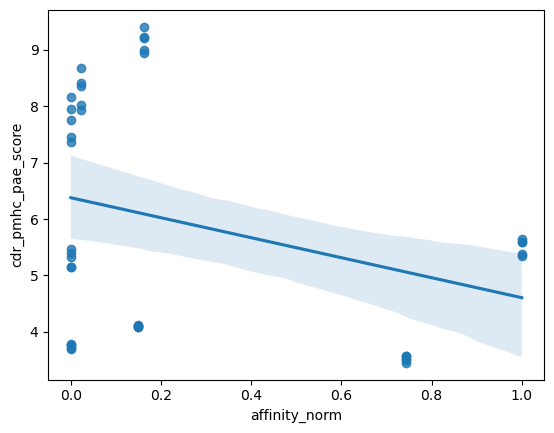

In [28]:
sns.regplot(confidence_scores, x='affinity_norm', y='cdr_pmhc_pae_score')

plt.show()

In [29]:
result = pg.corr(confidence_scores['affinity_norm'], confidence_scores['cdr_pmhc_pae_score'], alternative='less')

print(f"R^2 = {result.iloc[0]['r'] ** 2:.2f}")
result

R^2 = 0.10


,n,r,CI95%,p-val,BF10,power
pearson,40,-0.313951,"[-1.0, -0.05]",0.024257,2.507,0.639587
